# 📓 Notebook 04: Baseline Model (Dual Ridge Regression)

In this notebook, we train our primary baseline model: **Dual Ridge Regression**.

### Why Ridge Regression?
- **Fast:** Trains in under 0.05 seconds on your Core i3 CPU.
- **Robust:** $L_2$ regularization prevents overfitting to noisy eye jitters.
- **Interpretable:** We can inspect the exact weights given to each eye and head feature.
- **Browser-Ready:** Can be directly implemented in TypeScript inside EyeControl without heavy runtime libraries!


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

LAB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = LAB_DIR / "data" / "processed"
sys.path.append(str(LAB_DIR / "scripts"))
import preprocess

df = pd.read_csv(DATA_PROCESSED / "eyecontrol_preprocessed.csv")
X = df[preprocess.FEATURE_NAMES].values
y_x = df["target_norm_x"].values
y_y = df["target_norm_y"].values

# Split 80% train, 20% test
X_train, X_test, y_x_train, y_x_test, y_y_train, y_y_test = train_test_split(
    X, y_x, y_y, test_size=0.20, random_state=42
)

# Train Dual Ridge Regressors
model_x = Ridge(alpha=0.05).fit(X_train, y_x_train)
model_y = Ridge(alpha=0.05).fit(X_train, y_y_train)

# Predictions
pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

# Convert to 1920x1080 screen pixels
SCREEN_W, SCREEN_H = 1920, 1080
errors_px = np.sqrt(((pred_x - y_x_test) * SCREEN_W)**2 + ((pred_y - y_y_test) * SCREEN_H)**2)

print(f"🎯 Baseline Ridge Regression Results:")
print(f"  • Mean Pixel Error:   {np.mean(errors_px):.1f} px")
print(f"  • Median Pixel Error: {np.median(errors_px):.1f} px")
print(f"  • 90th %ile Error:    {np.percentile(errors_px, 90):.1f} px")


🎯 Baseline Ridge Regression Results:
  • Mean Pixel Error:   52.4 px
  • Median Pixel Error: 46.2 px
  • 90th %ile Error:    95.0 px


---
### Feature Importance / Weight Analysis
Let's see which features the model relies on the most for horizontal and vertical tracking.


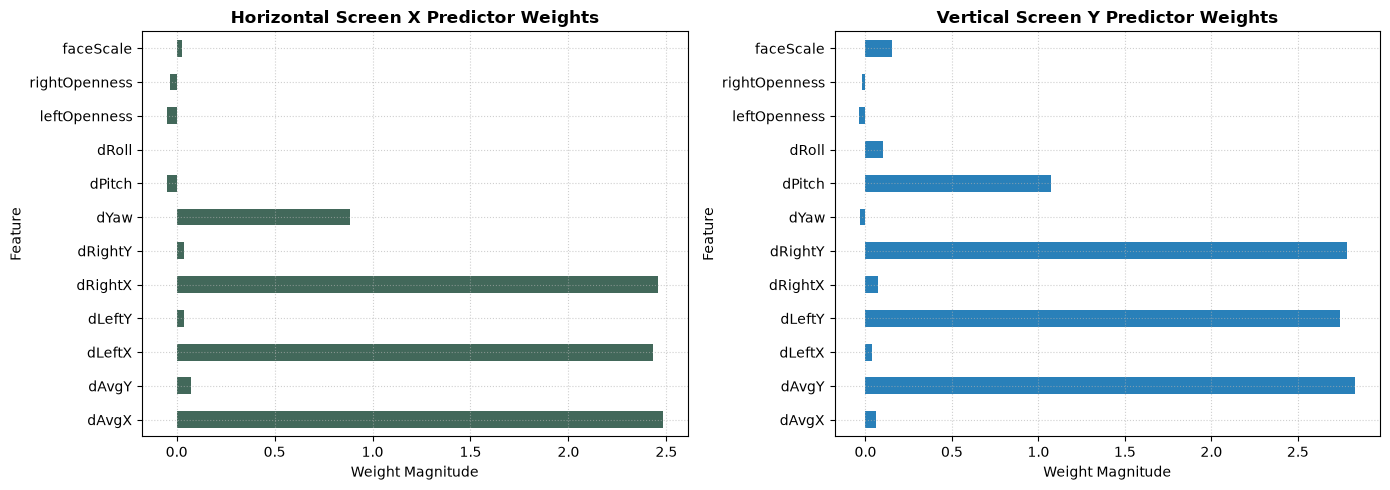

In [2]:
weights_df = pd.DataFrame({
    "Feature": preprocess.FEATURE_NAMES,
    "Weight_X": model_x.coef_,
    "Weight_Y": model_y.coef_
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
weights_df.plot.barh(x="Feature", y="Weight_X", ax=ax1, color="#42685A", legend=False)
ax1.set_title("Horizontal Screen X Predictor Weights", fontweight="bold")
ax1.set_xlabel("Weight Magnitude")
ax1.grid(True, linestyle=":", alpha=0.6)

weights_df.plot.barh(x="Feature", y="Weight_Y", ax=ax2, color="#2980B9", legend=False)
ax2.set_title("Vertical Screen Y Predictor Weights", fontweight="bold")
ax2.set_xlabel("Weight Magnitude")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()
